In [ ]:
import time
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense, Activation, Dropout, Flatten, GlobalAveragePooling2D, BatchNormalization, ZeroPadding2D
from tensorflow.keras.optimizers import Adam, SGD, Adamax, RMSprop
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model, load_model, save_model
from keras.models import Sequential
#from tensorflow.keras.applications import imagenet_utils
from sklearn.metrics import confusion_matrix
#from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
#from tensorflow.keras.applications.xception import Xception, preprocess_input
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input #SGD #299,299
#from tensorflow.keras.applications.inception_resnet_v2 import InceptionResNetV2, preprocess_input #299
#from tensorflow.keras.applications.efficientnet_v2 import EfficientNetV2S, preprocess_input #RMSProp # no inpt 224
#from tensorflow.keras.applications.efficientnet import EfficientNetB7, preprocess_input #224
#from tensorflow.keras.applications.efficientnet import EfficientNetB0, preprocess_input #224
#from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input #224
#from tensorflow.keras.applications.densenet import DenseNet201, preprocess_input #224 sgd 64 batch
from tensorflow.keras.preprocessing import image
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import precision_score, f1_score, recall_score, accuracy_score, roc_auc_score
import itertools
#import os
#import shutil
import matplotlib.pyplot as plt
#import zipfile
#from glob import glob
#import random
#import cv2

In [ ]:
!unzip "/content/drive/MyDrive/lise makale data/200X_CNN_data.zip"

In [ ]:
train_path = '/content/200X_Data_CNN_DATA/train'
test_path = '/content/200X_Data_CNN_DATA/test'

In [ ]:
batch_size = 32

train_data_generator = ImageDataGenerator(
            preprocessing_function=preprocess_input,
            validation_split=0.1,
            rotation_range= 5,
            brightness_range=[0.5, 1.5],
            zoom_range =0.2
            #rotation_range= 5,
            #brightness_range=[1, 1.5],
            #horizontal_flip= True,
            #vertical_flip = True
            )

            # width_shift_range=0,
            # height_shift_range= 0,
            # shear_range=0,
            # zoom_range= 0,
            #rescale=1.0/255.0,
            #brightness_range=0,
            # ,fill_mode='nearest'
            # )
traindata = train_data_generator.flow_from_directory(
            directory= train_path,
            subset="training",
            batch_size= batch_size,
            shuffle=True,
            target_size=(299,299))

validationdata = train_data_generator.flow_from_directory(
            directory= train_path,
            subset="validation",
            batch_size=batch_size,
            shuffle=True,
            target_size=(299,299))

testdata= ImageDataGenerator(preprocessing_function=preprocess_input).flow_from_directory(
            directory=test_path,
            batch_size=batch_size,
            target_size=(299, 299),
            shuffle=False)

train_size = len(train.filenames)
validation_size = len(validation.filenames)


Found 831 images belonging to 8 classes.
Found 88 images belonging to 8 classes.
Found 398 images belonging to 8 classes.


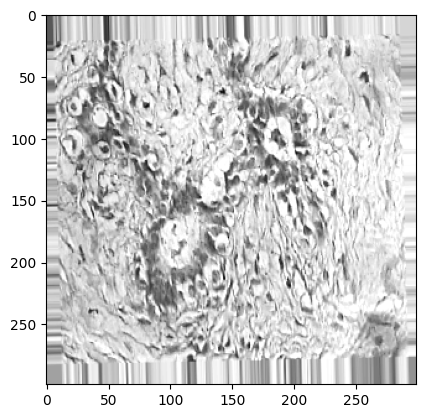

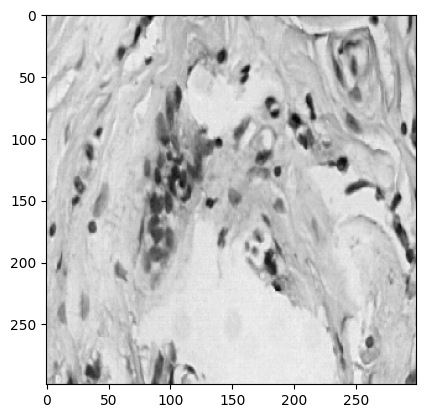

In [ ]:
p = traindata.next()
plt.imshow(p[0][0][:,:,0], cmap='gray')
plt.show()

t = testdata.next()
plt.imshow(t[0][0][:,:,0], cmap='gray')
plt.show()


In [ ]:
res = InceptionV3(input_shape = (299, 299, 3), weights='imagenet', include_top= False)

x = Dropout(.1)(res.output)
x = GlobalAveragePooling2D()(x)
#x = GlobalAveragePooling2D()(res.output)
#x = Flatten()(x)
#x = Dropout(.2)(x)
#x = Dense(units=2056, activation='relu')(x)
#x = Dense(units=1028, activation='relu')(x)
output = Dense(units=8, activation='softmax')(x)
#output = Dense(units=5, activation='sigmoid')(x)
model = Model(inputs=res.input, outputs=output)



In [ ]:
for layer in model.layers[:]:
    layer.trainable = False

for layer in model.layers[-20:]:
    layer.trainable = True

for i, layer in enumerate(model.layers): print(i, layer.name, layer.trainable)

model.compile(optimizer=SGD(learning_rate=0.01), loss='categorical_crossentropy', metrics=['accuracy'])

es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=22)

reduce_lr = ReduceLROnPlateau(monitor='val_loss',
                              factor=0.2,
                              patience=5,
                              verbose=2,
                              min_delta=0.0001)

checkpoint_filepath = "./check_pointaccyeni"
model_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=False,
    monitor='val_accuracy',
    mode='max',
    save_best_only=True)

checkpoint_filepath = "./check_pointlosyeni"
model_checkpoint_callback_loss = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=False,
    monitor='val_loss',
    mode='min',
    save_best_only=True)

start = time.time()

In [ ]:
history = model.fit(traindata,
                    steps_per_epoch=(train_size//batch_size),
                    validation_data=validation_generator,
                    validation_steps=(validation_size//batch_size),
                    epochs= 100 ,
                    callbacks=[model_checkpoint_callback, model_checkpoint_callback_loss, reduce_lr, es],
                    verbose=1
                    )

# Timer stop
stop = time.time()
tr_tm = stop - start
print(f"Training time: {stop - start}s")

save_model(
    model,
    filepath = './modelendyeni',
    overwrite=True,
    include_optimizer=True,
    save_format= None,
    signatures=None,
    options=None
)

Epoch 1/100


In [ ]:
import keras
# Calling `save('my_model')` creates a SavedModel folder `my_model`.
model.save("/content/drive/MyDrive/lise makale/VGG16/train 1/vgg16.h5")


In [ ]:

plt.plot(history.history['loss'], label='Loss (Training dataset)')
plt.plot(history.history['val_loss'], label='Loss (Validation dataset)')
plt.title('Loss Graph')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(loc="upper left")
plt.show()

# Plot history: Accuracy
plt.plot(history.history['accuracy'], label='Accuracy (Training dataset)')
plt.plot(history.history['val_accuracy'], label='Accuracy  (Validation dataset)')
plt.title('Accuracy Graph')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc="upper left")
plt.show()



In [ ]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    #thresh = cm.max() / 2.   Kontrast sorunu nedeniyle aşağıdaki kodu kullan
    thresh = cm.min()+(cm.max() - cm.min()) / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        if normalize:
            plt.text(j, i, format(cm[i, j], '.2f'),
                horizontalalignment="center",
                color="white" if cm[i, j] > thresh else "black")
        else:
            plt.text(j, i, cm[i, j],
                horizontalalignment="center",
                color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True Labels')
    plt.xlabel('Predicted Labels')
    plt.show()

loadmodel = load_model(
    filepath = r'/content/drive/MyDrive/lise makale data/inception/modelendyeni',
    custom_objects=None,
    compile=True
)


In [ ]:
predictions_1 = loadmodel.predict(testdata, verbose=1)


Confusion matrix, without normalization
[[21  1  3  0  5  1  0  3]
 [ 1 23 10 12  8  3  1  2]
 [ 0  3 58  6  2  1  4  6]
 [ 0  7  8 29  1  0  3  1]
 [ 0  7  8  4 39  1  0  0]
 [ 0  5  4  1  2 21  4  4]
 [ 2  1 13  0  2  2 13  0]
 [ 2  2 11  0  1  1  0 25]]


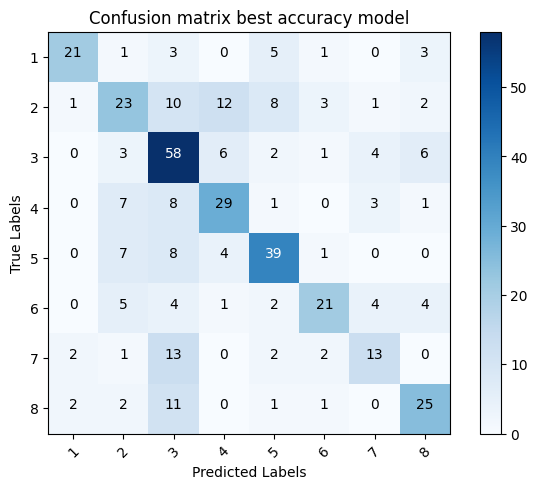

Micro Precision: 0.575377 
Micro Recall: 0.575377 
Micro F1: 0.575377


Acuracy: 0.575377 
Macro Precision: 0.602360 
Macro Recall: 0.560026 
Macro F1: 0.573606


Weighted Precision: 0.585727 
Weighted Recall: 0.575377 
Weighted F1: 0.572537


In [ ]:
test_labels = testdata.classes
cm_plot_labels = ['1','2','3','4','5','6','7','8']


cm2 = confusion_matrix(y_true=test_labels, y_pred=predictions_1.argmax(axis=1))
plot_confusion_matrix(cm=cm2, classes=cm_plot_labels, title='Confusion matrix best accuracy model')


y_true=testdata.classes
y_pred=predictions_1.argmax(axis=1)

print("Micro Precision: %f "%precision_score(y_true, y_pred, average='micro'))
print("Micro Recall: %f "%recall_score(y_true, y_pred, average='micro'))
print("Micro F1: %f"% f1_score(y_true, y_pred, average='micro'))
#print("AUC Score: %f"%roc_auc_score(y_true, y_pred, average='micro'))
print("\n")

print("Acuracy: %f "%accuracy_score(y_true, y_pred))
print("Macro Precision: %f "%precision_score(y_true, y_pred, average='macro'))
print("Macro Recall: %f "%recall_score(y_true, y_pred, average='macro'))
print("Macro F1: %f"% f1_score(y_true, y_pred, average='macro'))
#print("AUC Score: %f"%roc_auc_score(y_true, y_pred, average='macro'))
print("\n")

print("Weighted Precision: %f "%precision_score(y_true, y_pred, average='weighted'))
print("Weighted Recall: %f "%recall_score(y_true, y_pred, average='weighted'))
print("Weighted F1: %f"% f1_score(y_true, y_pred, average='weighted'))
#print("ROC_AUC Score: %f"%roc_auc_score(y_true, y_pred, average='weighted'))